# Are millennials dying of alcohol-related liver disease more than past generations?

**Question:** At the same age, do millennials have higher liver cirrhosis death rates than Gen X, Boomers, and the Silent Generation?

**Approach:** Take U.S. age-specific cirrhosis death rates (1970–2023), estimate each data point's birth year as *year of death − midpoint of the age group*, assign a generation, and compare generations at the same ages. Cirrhosis is used as a long-running proxy for heavy-drinking mortality because consistent "alcohol-induced death" series by age don't go back before 1999.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/cirrhosis_rates_by_age_1970_2023.csv', index_col='year')
df.tail()

,25-34,35-44,45-54,55-64,65-74,75-84,85+
year,,,,,,,
2017,2.1,7.6,20.3,34.2,35.2,35.5,29.3
2018,2.3,7.7,20.3,34.6,36.2,37.6,28.4
2019,2.5,8.4,20.5,35.5,37.3,37.9,29.6
2022,3.9,12.6,23.3,39.2,39.0,36.7,30.2
2023,3.6,11.3,21.9,35.3,37.5,37.0,33.5


## 1. Reshape into a cohort view

In [2]:
MID_AGE = {'25-34': 30, '35-44': 40, '45-54': 50, '55-64': 60}

def generation(birth_year):
    if birth_year <= 1945: return 'Silent'
    if birth_year <= 1964: return 'Boomer'
    if birth_year <= 1980: return 'Gen X'
    if birth_year <= 1996: return 'Millennial'
    return 'Gen Z'

long = (df[list(MID_AGE)].reset_index()
          .melt(id_vars='year', var_name='age', value_name='rate'))
long['birth'] = long['year'] - long['age'].map(MID_AGE)
long['gen'] = long['birth'].apply(generation)
long.head()

,year,age,rate,birth,gen
0,1970,25-34,4.4,1940,Silent
1,1971,25-34,4.2,1941,Silent
2,1972,25-34,4.3,1942,Silent
3,1973,25-34,4.2,1943,Silent
4,1974,25-34,4.2,1944,Silent


## 2. Compare generations at the same age

In [3]:
ORDER = ['Silent', 'Boomer', 'Gen X', 'Millennial']
summary = (long[long.gen.isin(ORDER)]
           .groupby(['age', 'gen'])
           .agg(mean_rate=('rate', 'mean'), n_years=('rate', 'size'),
                first_year=('year', 'min'), last_year=('year', 'max'))
           .round(2))
summary = summary.reindex(ORDER, level='gen')
summary

mean_rate  n_years  first_year  last_year
age   gen                                                  
25-34 Silent           4.17        6        1970       1975
      Boomer           2.75       19        1976       1994
      Gen X            1.12       16        1995       2010
      Millennial       2.25       11        2011       2023
35-44 Silent          15.08       16        1970       1985
      Boomer           8.54       19        1986       2004
      Gen X            6.74       15        2005       2019
      Millennial      11.95        2        2022       2023
45-54 Silent          26.85       26        1970       1995
      Boomer          18.61       19        1996       2014
      Gen X           21.07        7        2015       2023
55-64 Silent          34.16       36        1970       2005
      Boomer          31.09       16        2006       2023

In [4]:
gx = df.loc[1995:2010, '25-34'].mean()
mil = df.loc[2015:2023, '25-34'].mean()
print(f'Ages 25-34: millennial era (2015-23) = {mil:.2f}, Gen X era (1995-2010) = {gx:.2f}  ->  {mil/gx:.1f}x')

Ages 25-34: millennial era (2015-23) = 2.66, Gen X era (1995-2010) = 1.12  ->  2.4x


## 3. Period check: did every age group get worse, or just young adults?

In [5]:
baseline = df.loc[2000:2004].mean()
((df.loc[[2019, 2022, 2023]] / baseline - 1) * 100).round(0)

,25-34,35-44,45-54,55-64,65-74,75-84,85+
year,,,,,,,
2019,145.0,16.0,11.0,52.0,27.0,24.0,32.0
2022,282.0,74.0,27.0,68.0,32.0,20.0,35.0
2023,253.0,56.0,19.0,52.0,27.0,21.0,49.0


## 4. Visualize

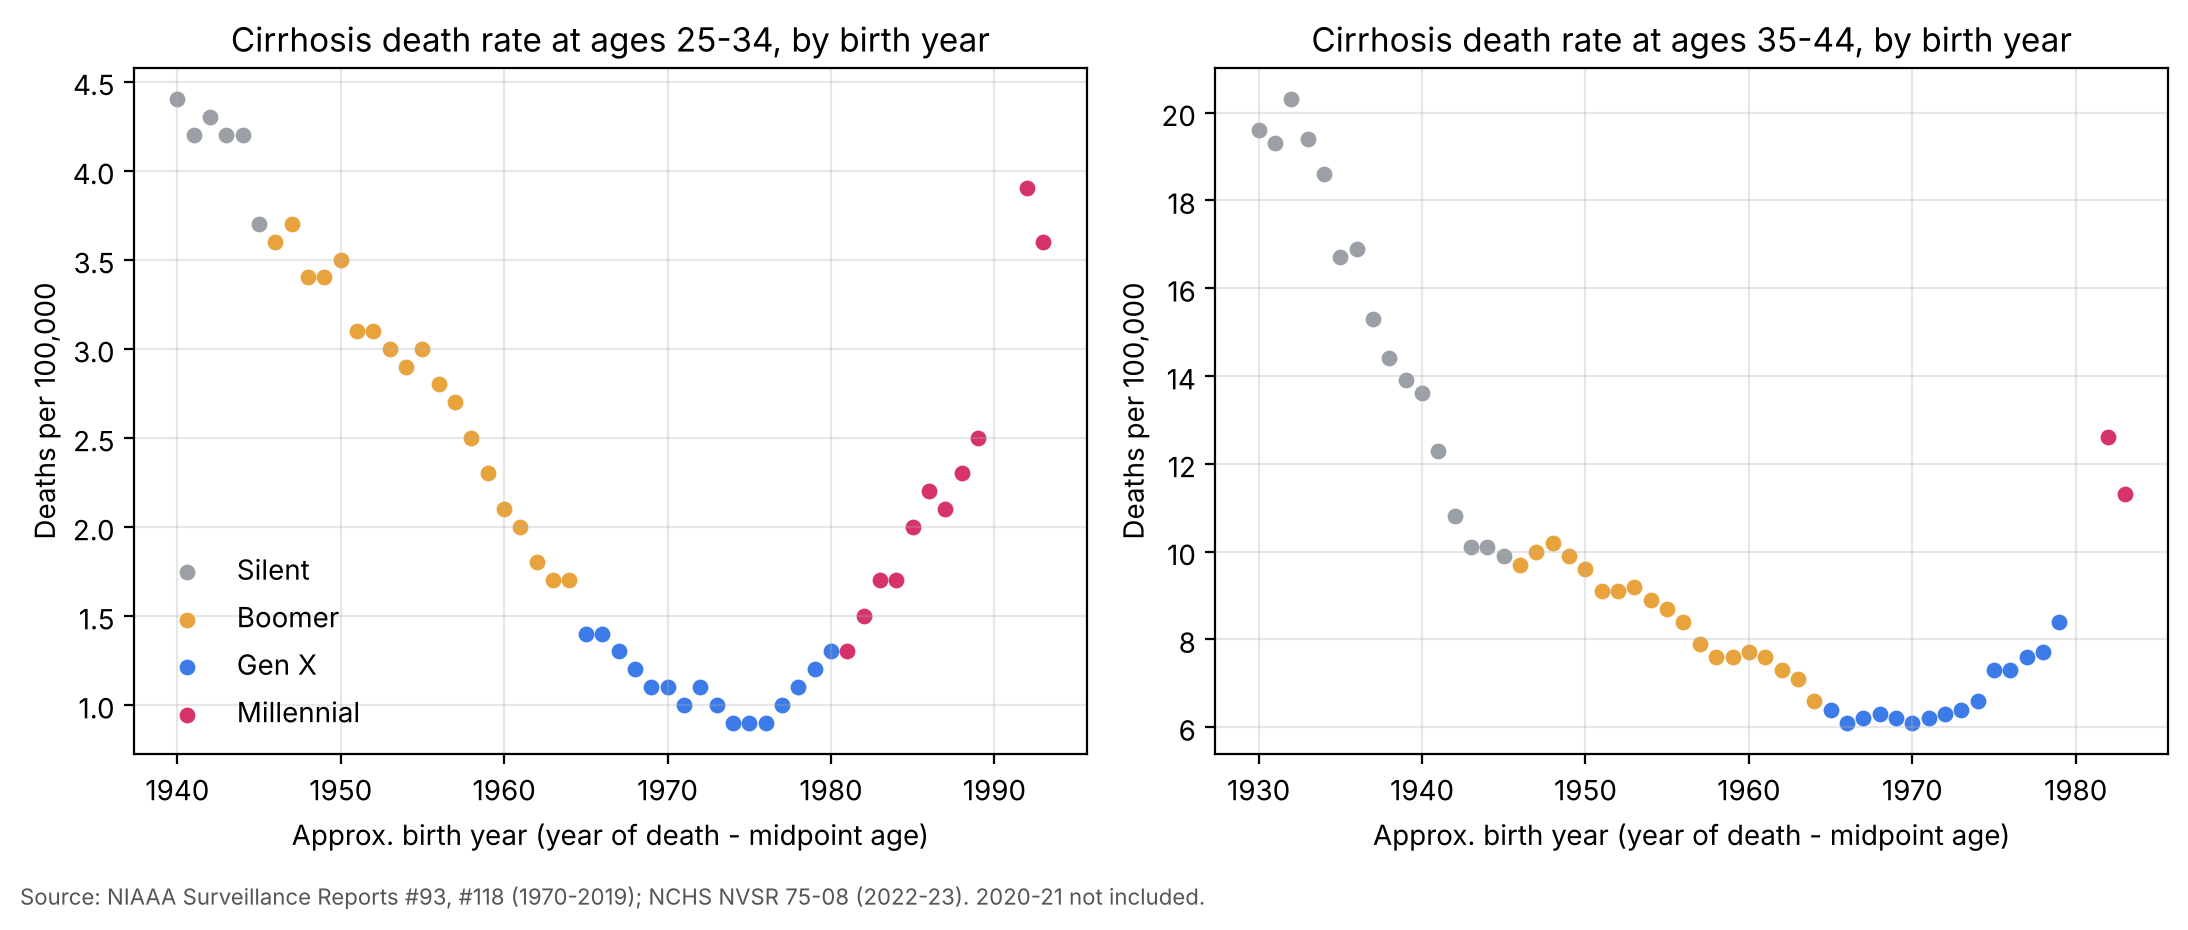

In [6]:
COLORS = {'Silent': '#9aa0a6', 'Boomer': '#e8a33d', 'Gen X': '#3d7be8', 'Millennial': '#d6336c'}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, age in zip(axes, ['25-34', '35-44']):
    sub = long[long.age == age]
    for g in ORDER:
        d = sub[sub.gen == g]
        ax.scatter(d.birth, d.rate, c=COLORS[g], label=g, s=22)
    ax.set_title(f'Cirrhosis death rate at ages {age}, by birth year')
    ax.set_xlabel('Approx. birth year (year of death - midpoint age)')
    ax.set_ylabel('Deaths per 100,000')
    ax.grid(alpha=0.3)
axes[0].legend(frameon=False)
fig.text(0.01, 0.005, 'Source: NIAAA Surveillance Reports #93, #118 (1970-2019); NCHS NVSR 75-08 (2022-23). 2020-21 not included.',
         fontsize=8, color='#555')
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig('../figures/cohort_chart.png', dpi=160)
plt.show()

## Findings

- **Millennials vs. Gen X:** at ages 25–34, millennials' cirrhosis death rate is about **2.4×** Gen X's at the same age. Every birth year since roughly 1975 has done worse than the one before.
- **Not a record:** the Silent Generation had higher rates at the same ages. The long-run pattern is a **U shape**: decades of decline, a low point with Gen X, then a reversal.
- **Both period and cohort effects:** since 2000–04, rates rose 20–70% in older age groups but about 250% among 25–34-year-olds — a general rise, plus a much steeper one for young adults.

## Limitations

- Cirrhosis has non-alcohol causes (hepatitis B/C, fatty liver disease). Higher hepatitis C prevalence in older cohorts likely inflates their rates somewhat.
- 2020–2021 (the pandemic peak for alcohol deaths) are missing.
- 2022–2023 come from NCHS rather than NIAAA; definitions are close but not identical.
- Birth years are approximated from 10-year age bands; generation cutoffs are conventions.
- This is descriptive. It shows *when* rates changed, not *why* — it does not test causes like advertising, the 2008 recession, or obesity.